# Prática — Módulo 2: Linguagem Natural e Desafios Computacionais


## Prática
O objetivo desta prática é operacionalizar as etapas iniciais do pipeline de PLN a partir de um texto controlado e, em seguida, de um texto real coletado da Wikipedia. O aluno executa tokenização com split(), NLTK e spaCy, compara stemming e lematização, analisa classes gramaticais (POS), reconhecimento de entidades nomeadas (NER), aplica remoção de stopwords e calcula frequência de termos, tornando explícito como cada decisão de pré-processamento altera a representação computacional do texto; não há treinamento de modelos, apenas análise estrutural.

## Dataset
O dataset consiste em um único documento textual em português obtido por requisição HTTP à página da Wikipedia sobre Inteligência Artificial, com extração dos parágrafos HTML e concatenação em uma única string. O texto enciclopédico, formal e tecnicamente denso, é utilizado como corpus de teste para observar como ferramentas de PLN estruturam linguisticamente um texto bruto antes de qualquer etapa de modelagem.


### Pergunta
1.	No texto base definido manualmente, qual é a unidade de análise inicial do experimento? Por que começamos com um texto controlado?



In [9]:
# Definir o texto base para experimentos iniciais.
texto = "Os pesquisadores estavam analisando os resultados obtidos pelas pesquisas anteriores e decidiram aplicar modelos estatísticos mais avançados para melhorar as previsões."
texto

'Os pesquisadores estavam analisando os resultados obtidos pelas pesquisas anteriores e decidiram aplicar modelos estatísticos mais avançados para melhorar as previsões.'

### Pergunta
2.	Ao aplicar split(), como o texto é segmentado? Que limitações aparecem imediatamente?

In [10]:
# Tokenizar usando split().
tokens_split = texto.split()
tokens_split

['Os',
 'pesquisadores',
 'estavam',
 'analisando',
 'os',
 'resultados',
 'obtidos',
 'pelas',
 'pesquisas',
 'anteriores',
 'e',
 'decidiram',
 'aplicar',
 'modelos',
 'estatísticos',
 'mais',
 'avançados',
 'para',
 'melhorar',
 'as',
 'previsões.']

## NLTK
O NLTK é uma biblioteca Python puro. Surgiu em **2001 com foco acadêmico e educacional**, sendo amplamente utilizado para ensino de fundamentos de Processamento de Linguagem Natural. Ele oferece diversos algoritmos clássicos, corpora e ferramentas modulares, porém **não foi projetado com prioridade em desempenho ou aplicações em produção**. Seu suporte ao português é limitado, destacando-se principalmente o **stemmer RSLP**, mas sem modelos estatísticos robustos integrados para POS tagging ou reconhecimento de entidades.

### Pergunta
3.	Compare split() com word_tokenize() do NLTK. O que muda no tratamento da pontuação?

In [11]:
# Tokenizar com NLTK.
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize

tokens_nltk = word_tokenize(texto, language='portuguese')
tokens_nltk

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


['Os',
 'pesquisadores',
 'estavam',
 'analisando',
 'os',
 'resultados',
 'obtidos',
 'pelas',
 'pesquisas',
 'anteriores',
 'e',
 'decidiram',
 'aplicar',
 'modelos',
 'estatísticos',
 'mais',
 'avançados',
 'para',
 'melhorar',
 'as',
 'previsões',
 '.']

### Pergunta
4.	Ao aplicar stemming com RSLPStemmer, que tipo de transformação ocorre nas palavras? As formas resultantes são linguisticamente válidas?

In [13]:
# Aplicar stemming com RSLPStemmer (português).
nltk.download('rslp')

from nltk.stem import RSLPStemmer

stemmer = RSLPStemmer()
stems = [stemmer.stem(token) for token in tokens_nltk]
list(zip(tokens_nltk, stems))

[nltk_data] Downloading package rslp to /root/nltk_data...
[nltk_data]   Package rslp is already up-to-date!


[('Os', 'os'),
 ('pesquisadores', 'pesquis'),
 ('estavam', 'est'),
 ('analisando', 'analis'),
 ('os', 'os'),
 ('resultados', 'result'),
 ('obtidos', 'obt'),
 ('pelas', 'pel'),
 ('pesquisas', 'pesquis'),
 ('anteriores', 'anteri'),
 ('e', 'e'),
 ('decidiram', 'decid'),
 ('aplicar', 'aplic'),
 ('modelos', 'model'),
 ('estatísticos', 'estatís'),
 ('mais', 'mais'),
 ('avançados', 'avanç'),
 ('para', 'par'),
 ('melhorar', 'melhor'),
 ('as', 'as'),
 ('previsões', 'previs'),
 ('.', '.')]

## spaCy
O spaCy é uma biblioteca Python, com seu núcleo otimizado em Cython (compila para código em C, mais rápido que Python puro. Foi lançado em **2015 com foco em aplicações reais e desempenho em produção**, possuindo arquitetura otimizada e pipeline integrado. Ele fornece modelos estatísticos treinados para português, incluindo **lematização, classes gramaticais e reconhecimento de entidades**, sendo mais moderno, mais rápido e mais adequado para projetos práticos e estruturados de PLN.

Você pode acessar a documentação em: https://spacy.io/api/


In [8]:
# O spaCy não vem instalado por padrão, então precisa ser instalado manualmente.
!pip install -U spacy
import spacy

# Baixar modelo em português.
!python -m spacy download pt_core_news_sm

nlp = spacy.load("pt_core_news_sm")


  Using cached https://github.com/explosion/spacy-models/releases/download/pt_core_news_sm-3.8.0/pt_core_news_sm-3.8.0-py3-none-any.whl (13.0 MB)
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [14]:
# Lematizar com spaCy o mesmo texto (comparar com stemming do NLTK).
doc = nlp(texto)

lemmas_spacy = [token.lemma_ for token in doc]
list(zip([t.text for t in doc], lemmas_spacy))

[('Os', 'o'),
 ('pesquisadores', 'pesquisador'),
 ('estavam', 'estar'),
 ('analisando', 'analisar'),
 ('os', 'o'),
 ('resultados', 'resultado'),
 ('obtidos', 'obter'),
 ('pelas', 'por o'),
 ('pesquisas', 'pesquisa'),
 ('anteriores', 'anterior'),
 ('e', 'e'),
 ('decidiram', 'decidir'),
 ('aplicar', 'aplicar'),
 ('modelos', 'modelo'),
 ('estatísticos', 'estatístico'),
 ('mais', 'mais'),
 ('avançados', 'avançar'),
 ('para', 'para'),
 ('melhorar', 'melhorar'),
 ('as', 'o'),
 ('previsões', 'previsão'),
 ('.', '.')]

### Pergunta
5.	Ao lematizar o mesmo texto com spaCy, qual a diferença estrutural em relação ao stemming?

In [15]:
# Comparar token original vs stem NLTK vs lemma spaCy.
import pandas as pd

df_comp = pd.DataFrame({
    "token": [t.text for t in doc],
    "stem_nltk": [stemmer.stem(t.text) for t in doc],
    "lemma_spacy": [t.lemma_ for t in doc],
})

df_comp

,token,stem_nltk,lemma_spacy
0,Os,os,o
1,pesquisadores,pesquis,pesquisador
2,estavam,est,estar
3,analisando,analis,analisar
4,os,os,o
5,resultados,result,resultado
6,obtidos,obt,obter
7,pelas,pel,por o
8,pesquisas,pesquis,pesquisa
9,anteriores,anteri,anterior


### Pergunta
6. Considerando aplicações modernas de PLN em língua portuguesa, qual abordagem tende a ser mais adequada: stemming ou lematização? Justifique com base em práticas atuais de mercado.

**Resposta**:
A lematização tende a ser mais adequada na maioria das aplicações modernas de PLN, pois preserva formas linguísticas válidas e mantém maior fidelidade semântica. Modelos atuais baseados em **embeddings e transformers** operam melhor com representações lexicalmente corretas. O stemming ainda é útil em cenários mais simples, como Bag-of-Words ou recuperação de informação, mas não é a prática predominante em sistemas contemporâneos.

Nesse contexto, as bibliotecas ocupam papéis distintos em português. O NLTK é utilizado principalmente para stemming, por meio do RSLPStemmer, sendo a opção prática quando se deseja redução dimensional em abordagens clássicas. Já o spaCy fornece modelos treinados para português com lematização consistente, além de POS tagging e reconhecimento de entidades integrados, compondo um pipeline moderno de processamento linguístico. Assim, quando o objetivo é aplicar stemming em português, utiliza-se tipicamente o NLTK; quando se busca lematização e análise estrutural mais robusta, o spaCy é a escolha predominante nas práticas atuais.

### Pergunta
7.	Ao extrair token.pos_, o que significa POS tagging? Que tipo de informação passa a estar disponível?

In [ ]:
# Taggear "Part Of Speech" (POS) com spaCy.
[(token.text, token.pos_) for token in doc]

[('Os', 'DET'),
 ('pesquisadores', 'NOUN'),
 ('estavam', 'AUX'),
 ('analisando', 'VERB'),
 ('os', 'DET'),
 ('resultados', 'NOUN'),
 ('obtidos', 'VERB'),
 ('pelas', 'ADP'),
 ('pesquisas', 'NOUN'),
 ('anteriores', 'ADJ'),
 ('e', 'CCONJ'),
 ('decidiram', 'VERB'),
 ('aplicar', 'VERB'),
 ('modelos', 'NOUN'),
 ('estatísticos', 'ADJ'),
 ('mais', 'ADV'),
 ('avançados', 'ADJ'),
 ('para', 'SCONJ'),
 ('melhorar', 'VERB'),
 ('as', 'DET'),
 ('previsões', 'NOUN'),
 ('.', 'PUNCT')]

### Pergunta
8.	Ao extrair token.dep_, token.pos_ e token.morph, que tipo de estrutura linguística passa a ser explicitada no texto? Que diferença existe entre classe gramatical e atributos morfológicos?

In [ ]:
# Extrair dependências sintáticas.
print(f"{'Token':15} {'Dep':12} {'Head':15}")
print("-"*42)
for token in doc:
    print(f"{token.text:15} {token.dep_:12} {token.head.text:15}")

print("\n")

Token           Dep          Head           
------------------------------------------
Os              det          pesquisadores  
pesquisadores   nsubj        analisando     
estavam         aux          analisando     
analisando      ROOT         analisando     
os              det          resultados     
resultados      obj          analisando     
obtidos         acl          resultados     
pelas           case         pesquisas      
pesquisas       obl:agent    obtidos        
anteriores      amod         pesquisas      
e               cc           decidiram      
decidiram       conj         analisando     
aplicar         xcomp        decidiram      
modelos         obj          aplicar        
estatísticos    amod         modelos        
mais            advmod       avançados      
avançados       amod         modelos        
para            mark         melhorar       
melhorar        acl          modelos        
as              det          previsões      
previsões   

In [ ]:
# POS (Part-of-Speech) e Morfologia.
print(f"{'Token':15} {'POS':10} {'Morfologia'}")
print("-"*50)
for token in doc:
    print(f"{token.text:15} {token.pos_:10} {token.morph}")

Token           POS        Morfologia
--------------------------------------------------
Os              DET        Definite=Def|Gender=Masc|Number=Plur|PronType=Art
pesquisadores   NOUN       Gender=Masc|Number=Plur
estavam         AUX        Mood=Ind|Number=Plur|Person=3|Tense=Imp|VerbForm=Fin
analisando      VERB       VerbForm=Ger
os              DET        Definite=Def|Gender=Masc|Number=Plur|PronType=Art
resultados      NOUN       Gender=Masc|Number=Plur
obtidos         VERB       Gender=Masc|Number=Plur|VerbForm=Part|Voice=Pass
pelas           ADP        Definite=Def|Gender=Fem|Number=Plur|PronType=Art
pesquisas       NOUN       Gender=Fem|Number=Plur
anteriores      ADJ        Gender=Fem|Number=Plur
e               CCONJ      
decidiram       VERB       Mood=Ind|Number=Plur|Person=3|Tense=Past|VerbForm=Fin
aplicar         VERB       VerbForm=Inf
modelos         NOUN       Gender=Masc|Number=Plur
estatísticos    ADJ        Gender=Masc|Number=Plur
mais            ADV        
avan

### Pergunta
9.	No primeiro teste de NER com texto simples, o modelo reconheceu entidades? O resultado foi consistente?

In [ ]:
# Extrair entidades nomeadas (NER) com spaCy.
doc = nlp(texto)
[(ent.text, ent.label_) for ent in doc.ents]

[]

### Pergunta
10.	No segundo teste com texto contendo entidades reais, como o modelo se comportou? Que tipos de entidades foram identificadas?

In [ ]:
# Testar NER com um texto que realmente contém entidades nomeadas.
texto_ner = "O professor Fulano ministra aulas no curso Ciência de Dados na Fatec em Votorantim, estado de SP."
doc = nlp(texto_ner)
[(ent.text, ent.label_) for ent in doc.ents]

[('Fulano', 'PER'),
 ('Ciência de Dados', 'MISC'),
 ('Fatec', 'ORG'),
 ('Votorantim', 'LOC'),
 ('SP', 'LOC')]

### Pergunta
11.	Ao coletar o texto da Wikipedia (scraping básico), o que muda em relação ao texto manual inicial em termos de complexidade linguística? A abordagem para filtrar o texto e eliminar marcações HTML é confiável?

In [ ]:
# Coletar texto da Wikipedia (scraping básico).
import requests
from bs4 import BeautifulSoup

url = "https://pt.wikipedia.org/wiki/Processamento_de_linguagem_natural"

# Simular o comportamento de navegador para que a wikipedia não bloqueie a requisição.
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/120.0.0.0 Safari/537.36"
}

resposta = requests.get(url, headers=headers)
resposta.text

'<!DOCTYPE html>\n<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available" lang="pt" dir="ltr">\n<head>\n<meta charset="UTF-8">\n<title>Processamento de linguagem natural – Wikipédia, a enciclopédia livre</title>\n<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabl

In [ ]:
# Elimina conteúdo desnecessário e mantém apenas texto.
soup = BeautifulSoup(resposta.text, "html.parser")
paragrafos = soup.find_all("p")

conteudo = " ".join([p.get_text() for p in paragrafos])
conteudo[:1000]

'Processamento de língua natural (PLN) é uma subárea da ciência da computação, inteligência artificial e da linguística que estuda os problemas da geração e compreensão automática de línguas humanas naturais. Sistemas de geração de língua natural convertem informação de bancos de dados de computadores em linguagem compreensível ao ser humano e sistemas de compreensão de língua natural convertem ocorrências de linguagem humana em representações mais formais, mais facilmente manipuláveis por programas de computador. Alguns desafios do PLN são compreensão de língua natural, fazer com que computadores extraiam sentido de linguagem humana ou natural e geração de língua natural.\n A história do PLN começou na década de 1950, quando Alan Turing publicou o artigo "Computing Machinery and Intelligence", que propunha o que agora é chamado de teste de Turing como critério de inteligência.\n Em 1954, a experiência de Georgetown envolveu a tradução automática de mais de sessenta frases russas para 

### Pergunta
12.	Ao visualizar tokens com POS e lemma no texto da Wikipedia, que diferenças aparecem em relação ao texto pequeno inicial?

In [ ]:
# Verificar tamanho do documento.
doc_wiki = nlp(conteudo)
len(doc_wiki)

2168

In [ ]:
# Visualizar 100 primeiros tokens com POS e lemma.
[(token.text, token.pos_, token.lemma_) for token in doc_wiki[:100]]

[('Processamento', 'PROPN', 'processamento'),
 ('de', 'ADP', 'de'),
 ('língua', 'NOUN', 'língua'),
 ('natural', 'ADJ', 'natural'),
 ('(', 'PUNCT', '('),
 ('PLN', 'PROPN', 'PLN'),
 (')', 'PUNCT', ')'),
 ('é', 'AUX', 'ser'),
 ('uma', 'DET', 'um'),
 ('subárea', 'NOUN', 'subárea'),
 ('da', 'ADP', 'de o'),
 ('ciência', 'NOUN', 'ciência'),
 ('da', 'ADP', 'de o'),
 ('computação', 'NOUN', 'computação'),
 (',', 'PUNCT', ','),
 ('inteligência', 'NOUN', 'inteligência'),
 ('artificial', 'ADJ', 'artificial'),
 ('e', 'CCONJ', 'e'),
 ('da', 'ADP', 'de o'),
 ('linguística', 'NOUN', 'linguística'),
 ('que', 'PRON', 'que'),
 ('estuda', 'VERB', 'estudar'),
 ('os', 'DET', 'o'),
 ('problemas', 'NOUN', 'problema'),
 ('da', 'ADP', 'de o'),
 ('geração', 'NOUN', 'geração'),
 ('e', 'CCONJ', 'e'),
 ('compreensão', 'NOUN', 'compreensão'),
 ('automática', 'ADJ', 'automático'),
 ('de', 'ADP', 'de'),
 ('línguas', 'NOUN', 'língua'),
 ('humanas', 'ADJ', 'humano'),
 ('naturais', 'ADJ', 'natural'),
 ('.', 'PUNCT', '.'),

### Pergunta
13.	Ao analisar as entidades nomeadas da Wikipedia, houve algum erro de classificação? O que isso revela sobre o modelo?

In [ ]:
# Visualizar 100 primeiras entidades nomeadas.
[(ent.text, ent.label_) for ent in doc_wiki.ents[:50]]

[('PLN', 'ORG'),
 ('PLN', 'ORG'),
 ('Alan Turing', 'PER'),
 ('Computing Machinery and Intelligence', 'MISC'),
 ('Turing', 'PER'),
 ('Georgetown', 'LOC'),
 ('ALPAC', 'MISC'),
 ('SHRDLU', 'LOC'),
 ('ELIZA', 'PER'),
 ('Joseph Weizenbaum', 'PER'),
 ('ELIZA', 'PER'),
 ('ELIZA', 'PER'),
 ('Minha', 'LOC'),
 ('MARGIE', 'MISC'),
 ('SCHANK', 'ORG'),
 ('SAM', 'ORG'),
 ('CULLINGFORD', 'ORG'),
 ('PAM', 'ORG'),
 ('WILENSKY', 'ORG'),
 ('TaleSpin', 'MISC'),
 ('MEEHAN', 'MISC'),
 ('QUALM', 'ORG'),
 ('LEHNERT', 'ORG'),
 ('Politics', 'MISC'),
 ('CARBONELL', 'MISC'),
 ('Plot Units', 'PER'),
 ('LEHNERT', 'ORG'),
 ('PARRY', 'ORG'),
 ('Racter', 'PER'),
 ('Jabberwacky', 'MISC'),
 ('Lei de Moore', 'MISC'),
 ('Markov', 'PER'),
 ('PLN', 'ORG'),
 ('IBM', 'ORG'),
 ('Parlamento do', 'ORG'),
 ('Canadá', 'LOC'),
 ('União Europeia', 'ORG'),
 ('World Wide Web', 'MISC'),
 ('NLL', 'ORG'),
 ('ACL', 'ORG'),
 ('NLL', 'ORG'),
 ('Sumarização automática\n ', 'MISC'),
 ('Análise do Discurso\n Maquina', 'MISC'),
 ('Segmentação',

### Pergunta
14.	Ao filtrar tokens relevantes (removendo stopwords e pontuação), que tipo de informação está sendo descartada?

In [ ]:
# Filtrar tokens relevantes para análise lexical (BoW / frequência).
tokens_filtrados = [
    token.text.lower()          # Normaliza para minúsculas.
    for token in doc_wiki
    if not token.is_stop        # Remove stopwords (artigos, preposições, pronomes etc.).
    and not token.is_punct      # Remove sinais de pontuação.
    and not token.is_space      # Remove espaços e quebras de linha.
    and token.is_alpha          # Mantém apenas palavras formadas por letras.
]

tokens_filtrados[:50]

['processamento',
 'língua',
 'natural',
 'pln',
 'subárea',
 'ciência',
 'computação',
 'inteligência',
 'artificial',
 'linguística',
 'estuda',
 'problemas',
 'geração',
 'compreensão',
 'automática',
 'línguas',
 'humanas',
 'naturais',
 'sistemas',
 'geração',
 'língua',
 'natural',
 'convertem',
 'informação',
 'bancos',
 'dados',
 'computadores',
 'linguagem',
 'compreensível',
 'humano',
 'sistemas',
 'compreensão',
 'língua',
 'natural',
 'convertem',
 'ocorrências',
 'linguagem',
 'humana',
 'representações',
 'formais',
 'facilmente',
 'manipuláveis',
 'programas',
 'computador',
 'desafios',
 'pln',
 'compreensão',
 'língua',
 'natural',
 'computadores']

### Pergunta
15.	Na geração de frequência de termos, o que passa a ser considerado “importante”? O que essa decisão ignora?

In [ ]:
# Gerar frequência de termos.
from collections import Counter

bow_wiki = Counter(tokens_filtrados)
bow_wiki.most_common(20)

[('pln', 18),
 ('avaliação', 17),
 ('dados', 16),
 ('aprendizagem', 16),
 ('automática', 15),
 ('sistemas', 14),
 ('linguagem', 11),
 ('algoritmos', 11),
 ('natural', 10),
 ('língua', 9),
 ('tradução', 9),
 ('tarefas', 9),
 ('regras', 8),
 ('modelos', 8),
 ('entanto', 7),
 ('pesquisa', 7),
 ('entrada', 7),
 ('muitas', 7),
 ('análise', 7),
 ('processamento', 6)]

### Pergunta
16.	Ao observar a nuvem de palavras gerada após a remoção de stopwords e pontuação, quais termos se destacam como mais frequentes? Essa visualização reflete adequadamente o tema central do texto?

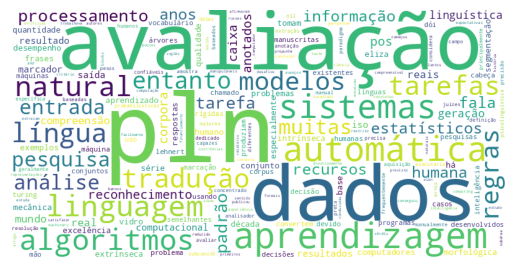

In [ ]:
# Gerar nuvem de palavras.
!pip install wordcloud

from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(width=800, height=400, background_color="white") \
    .generate_from_frequencies(bow_wiki)

plt.imshow(wordcloud)
plt.axis("off")
plt.show()

## One-Hot, BoW e TF-IDF
São técnicas clássicas de vetorização textual:
- Tradicionais baseadas em frequência/ocorrência.
- Produzem representações esparsas e de alta dimensionalidade.
- Não capturam semântica nem contexto.

In [ ]:
# Gerar one-hot por token (vocabulário fixo) para um exemplo simples.
import numpy as np

frase = "modelo de análise de dados"
tokens = frase.split()

vocab = ["modelo", "análise", "dados", "processamento"]
idx = {t:i for i,t in enumerate(vocab)}

onehots = []
for tok in tokens:
    if tok in idx:
        v = np.zeros(len(vocab), dtype=int)
        v[idx[tok]] = 1
        onehots.append((tok, v))

onehots

[('modelo', array([1, 0, 0, 0])),
 ('análise', array([0, 1, 0, 0])),
 ('dados', array([0, 0, 1, 0]))]

In [ ]:
# Gerar Bag-of-Words (contagens) para o documento no mesmo vocabulário.
import numpy as np

frase = "modelo de análise de dados com dados"
tokens = frase.split()

vocab = ["modelo", "análise", "dados"]
idx = {t:i for i,t in enumerate(vocab)}

bow = np.zeros(len(vocab), dtype=int)
for tok in tokens:
    if tok in idx:
        bow[idx[tok]] += 1

bow  # [modelo, análise, dados]

array([1, 1, 2])

In [ ]:
# calcular TF-IDF para um pequeno corpus usando sklearn.
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = [
    "modelo de análise de dados",
    "modelo estatístico aplicado",
    "dados públicos governamentais"
]

vectorizer = TfidfVectorizer(vocabulary=["modelo", "análise", "dados"])
X = vectorizer.fit_transform(corpus)

X.toarray()  # matriz TF-IDF (linhas = documentos, colunas = vocabulário)

array([[0.51785612, 0.68091856, 0.51785612],
       [1.        , 0.        , 0.        ],
       [0.        , 0.        , 1.        ]])